In [63]:
import pandas as pd
import re
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
import numpy as np 
from sklearn.model_selection import train_test_split
import statsmodels.api as sm 
import seaborn as sns
import matplotlib.pyplot as plt

Loading Table 1 and Table 5 from first cohort 

In [2]:
df1_samples = pd.read_excel("data/Table_S1_Participant_and_samples.xlsx", sheet_name = "Sample phenotype")
df2_species = pd.read_excel("data/Table_S5_Metagenomics_data.xlsx", sheet_name = "species")

Features are going to be our columns and participants will be our rows

In [3]:
df2_species = df2_species.set_index("Taxa")

#flip axis on df2 
df2_species = df2_species.T
df2_species.index.name = "iMSMS_ID" 
df2_species = df2_species.reset_index()

merged_samples_species = df1_samples.merge(df2_species, on = "iMSMS_ID", how = "inner")

In [4]:
print("df1", df1_samples.shape)
print("df2", df2_species.shape)
print("merged", merged_samples_species.shape)

df1 (1152, 60)
df2 (1152, 1678)
merged (1152, 1737)


In [5]:
print("number of columns:", len(merged_samples_species.columns)) 
print("number of rows:", len(merged_samples_species.index)) 
print("names of columns:", merged_samples_species.columns.tolist()) 
merged_samples_species = merged_samples_species.set_index("iMSMS_ID")
print("names of rows", merged_samples_species.index.tolist()) 

number of columns: 1737
number of rows: 1152
names of columns: ['iMSMS_ID', 'household', 'site', 'ethnicity', 'sex', 'age', 'weight', 'height', 'bmi', 'year_of_onset', 'disease', 'disease_course', 'disease_duration', 'treatment_status', 'treatments', 'administration', 'disease_course_control', 'treatment_control', 'treatments_control', 'diet_no_special_needs', 'diet_special_needs', 'spms_year', 'edss', 'MSSS', 'relapse_number', 'csf_results', 'dmt', 'children_number', 'roommates', 'birth_method', 'breastfeeding', 'allergies', 'allergy_specific', 'asthma', 'eating_disorder', 'eczema', 'anxiety', 'manic_depression_bipolar', 'ocd', 'depression', 'postpartum_depression', 'type2diabetes', 'ms_family', 'ocps_y_n', 'which_ocp', 'nsaids', 'nsaids_specifics', 'probiotics', 'rxmeds', 'rxmeds_number', 'otc_meds', 'otc_number', 'smoke', 'recreational_drug', 'weight_change', 'pets', 'education', 'occupation', 'vitamin D (IU)', 'Cohort', 'Megasphaera sp. UPII 135-E', 'Anaerocolumna xylanovorans', 'L

Removal of extra coulmns: 'iMSMS_ID', 'household', 'site', 'ethnicity', 'sex', 'age', 'weight', 'height', 'bmi', 'year_of_onset', 'disease', 'disease_course', 'disease_duration', 'treatment_status', 'treatments', 'administration', 'disease_course_control', 'treatment_control', 'treatments_control', 'diet_no_special_needs', 'diet_special_needs', 'spms_year', 'edss', 'MSSS', 'relapse_number', 'csf_results', 'dmt', 'children_number', 'roommates', 'birth_method', 'breastfeeding', 'allergies', 'allergy_specific', 'asthma', 'eating_disorder', 'eczema', 'anxiety', 'manic_depression_bipolar', 'ocd', 'depression', 'postpartum_depression', 'type2diabetes', 'ms_family', 'ocps_y_n', 'which_ocp', 'nsaids', 'nsaids_specifics', 'probiotics', 'rxmeds', 'rxmeds_number', 'otc_meds', 'otc_number', 'smoke', 'recreational_drug', 'weight_change', 'pets', 'education', 'occupation', 'vitamin D (IU)', 'Cohort'

In [6]:
cohort_pos = merged_samples_species.columns.get_loc("Cohort")
taxa_cols = merged_samples_species.columns[cohort_pos + 1:]
print("number of species features:", len(taxa_cols))

number of species features: 1677


In [7]:
data = merged_samples_species.iloc[:, merged_samples_species.columns.get_loc("Cohort") + 1:]
("Just Species Features Named:", data.columns.tolist())

('Just Species Features Named:',
 ['Megasphaera sp. UPII 135-E',
  'Anaerocolumna xylanovorans',
  'Lactobacillus perolens',
  'Bacillus sp. 916',
  'Catenibacterium mitsuokai',
  'Verrucomicrobia bacterium SCGC AAA164-L15',
  'Verrucomicrobia bacterium SCGC AAA164-O14',
  'Verrucomicrobia bacterium SCGC AAA168-E21',
  'Capnocytophaga gingivalis',
  'Solobacterium moorei',
  'Streptococcus didelphis',
  'Pseudomonas sp. StFLB209',
  'Flectobacillus major',
  'Prevotella sp. MSX73',
  'Brevibacterium senegalense',
  'Dielma fastidiosa',
  'Actinomyces coleocanis',
  'Actinomyces urogenitalis',
  'Riemerella columbina',
  'Clostridium sp. SY8519',
  'Serratia sp. ATCC 39006',
  'Lactobacillus frumenti',
  'Corynebacterium epidermidicanis',
  'Propionibacterium humerusii',
  'Ralstonia mannitolilytica',
  'Lactobacillus algidus',
  'Morococcus cerebrosus',
  'Anaerostipes caccae',
  'Rhodobacter capsulatus',
  'Pseudoflavonifractor capillosus',
  'Acinetobacter bereziniae',
  'Corynebacte

Final Species DF for Project:

In [8]:
data.head()

,Megasphaera sp. UPII 135-E,Anaerocolumna xylanovorans,Lactobacillus perolens,Bacillus sp. 916,Catenibacterium mitsuokai,Verrucomicrobia bacterium SCGC AAA164-L15,Verrucomicrobia bacterium SCGC AAA164-O14,Verrucomicrobia bacterium SCGC AAA168-E21,Capnocytophaga gingivalis,Solobacterium moorei,...,Oceanospirillum linum,Selenomonas ruminantium,Clostridium sp. ASF356,Eubacterium plexicaudatum,Lactobacillus mucosae,Roseimaritima ulvae,Saccharicrinis fermentans,Bifidobacterium reuteri,Lactobacillus kimchiensis,Tetrasphaera japonica
iMSMS_ID,,,,,,,,,,,,,,,,,,,,,
71401-0001,0.000013,7.563795e-06,0.000000e+00,0.0,0.000007,0.0,0.0,0.0,0.00000,0.000237,...,0.000000e+00,0.000002,0.000003,0.000074,0.000023,0.000000,1.163661e-06,0.000012,0.0,0.0
71401-0009,0.000038,4.471102e-07,0.000000e+00,0.0,0.000005,0.0,0.0,0.0,0.00000,0.000415,...,4.471102e-07,0.000000,0.000003,0.000112,0.000004,0.000000,4.471102e-07,0.000044,0.0,0.0
71401-0017,0.000028,1.509117e-06,5.030389e-07,0.0,0.000016,0.0,0.0,0.0,0.00000,0.000527,...,0.000000e+00,0.000000,0.000002,0.000065,0.000415,0.000000,0.000000e+00,0.000026,0.0,0.0
71401-0022,0.000005,8.353277e-07,0.000000e+00,0.0,0.000005,0.0,0.0,0.0,0.00002,0.000038,...,1.252992e-05,0.000000,0.000000,0.000079,0.000000,0.000002,0.000000e+00,0.000000,0.0,0.0
71401-0027,0.000011,0.000000e+00,0.000000e+00,0.0,0.000000,0.0,0.0,0.0,0.00000,0.000116,...,2.152702e-06,0.000001,0.000000,0.000041,0.000019,0.000000,0.000000e+00,0.000029,0.0,0.0


In [82]:
data.loc["71401-0001"].sum()

np.float64(1.0000000000000004)

Loading mmc3 and mmc4 sheets from second cohort 

In [9]:
df1_samples_02 = pd.read_excel("data/mmc3.xlsx", sheet_name = "Microbiome particpants")
df2_species_02 = pd.read_excel("data/mmc4.xlsx", sheet_name = "Species")

Merging on FD -- mmc4 sheet has FD combined with Registrant number ex) 32313_FD2917

In [10]:
id_col = df2_species_02.columns[0]
df2_species_02[id_col] = df2_species_02[id_col].astype(str).str.split("_").str[-1].str.strip()
df2_species_02 = df2_species_02.rename(columns = {id_col:"FD" })

In [11]:
merged_samples_species_02 = df1_samples_02.merge(df2_species_02, on = "FD", how = "inner")

In [12]:
print("df1", df1_samples_02.shape)
print("df2", df2_species_02.shape)
print("merged", merged_samples_species_02.shape)

df1 (187, 21)
df2 (187, 687)
merged (187, 707)


In [13]:
print("number of columns:", len(merged_samples_species_02.columns)) 
print("number of rows:", len(merged_samples_species_02.index)) 
print("names of columns:", merged_samples_species_02.columns.tolist())

number of columns: 707
number of rows: 187
names of columns: ['Registrant_number', 'sample_date', 'FD', 'Have serum gene sample', 'Recorded nutritional for at least 3 days', 'type', 'age', 'gender', 'BMI', 'diagnosis_date', 'treatment_group', 'treatment_start', 'treatment_end', 'treatment_duration', 'Registrant connected', 'Connection type', 'MS_type short', 'One_Relapse_or_more_during_following_year', 'worse_EDSS_after_one_year', 'worse_EDSS_after_one_year.1', 'Previous treatments', 'k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Enterobacterales|f__Enterobacteriaceae|g__Escherichia|s__Escherichia_marmotae|fSGB__2483|gSGB__6985|sSGB__10064', 'k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Enterobacterales|f__Enterobacteriaceae|g__Escherichia|s__Escherichia_coli|fSGB__2483|gSGB__6985|sSGB__10068', 'k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Enterobacterales|f__Enterobacteriaceae|g__Klebsiella|s__Klebsiella_pneumoniae|fSGB__2483|gSGB__6998|sSGB__10115', 'k

In [14]:
merged_samples_species_02 = merged_samples_species_02.set_index("FD") 
print("names of rows", merged_samples_species_02.index.tolist())

names of rows ['FD2917', 'FD2387', 'FD2901', 'FD2878', 'FD2298', 'FD2939', 'FD2912', 'FD2287', 'FD2369', 'FD2341', 'FD2880', 'FD2345', 'FD2894', 'FD2654', 'FD1888', 'FD2379', 'FD2358', 'FD2288', 'FD2652', 'FD2663', 'FD2657', 'FD2615', 'FD2627', 'FD2881', 'FD2823', 'FD2662', 'FD2375', 'FD2630', 'FD2920', 'FD1885', 'FD2324', 'FD2874', 'FD2389', 'FD2829', 'FD2363', 'FD1878', 'FD2625', 'FD2317', 'FD2330', 'FD2841', 'FD2902', 'FD2385', 'FD2383', 'FD2320', 'FD1876', 'FD1905', 'FD1867', 'FD2326', 'FD2635', 'FD2824', 'FD2373', 'FD2354', 'FD2626', 'FD2634', 'FD2825', 'FD2953', 'FD2956', 'FD2325', 'FD1882', 'FD2938', 'FD2331', 'FD2639', 'FD2368', 'FD2651', 'FD2284', 'FD2292', 'FD2297', 'FD2303', 'FD2306', 'FD2312', 'FD2329', 'FD2333', 'FD2335', 'FD2340', 'FD2339', 'FD2344', 'FD2342', 'FD2348', 'FD1860', 'FD1864', 'FD1866', 'FD1868', 'FD1871', 'FD1877', 'FD1890', 'FD1891', 'FD1894', 'FD1906', 'FD1908', 'FD1896', 'FD1899', 'FD1909', 'FD1913', 'FD1898', 'FD1904', 'FD1907', 'FD1901', 'FD1911', 'FD23

Removing extra colulmns: 

In [15]:
pt_pos = merged_samples_species_02.columns.get_loc("Previous treatments")
taxa_cols_02 = merged_samples_species_02.columns[pt_pos + 1:]
print("number of species features:", len(taxa_cols_02))

number of species features: 686


Almost Final Species 2 DF for Project:

In [16]:
data_2 = merged_samples_species_02.iloc[:, merged_samples_species_02.columns.get_loc("Previous treatments") + 1:]
data_2.head()

,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Enterobacterales|f__Enterobacteriaceae|g__Escherichia|s__Escherichia_marmotae|fSGB__2483|gSGB__6985|sSGB__10064,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Enterobacterales|f__Enterobacteriaceae|g__Escherichia|s__Escherichia_coli|fSGB__2483|gSGB__6985|sSGB__10068,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Enterobacterales|f__Enterobacteriaceae|g__Klebsiella|s__Klebsiella_pneumoniae|fSGB__2483|gSGB__6998|sSGB__10115,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Enterobacterales|f__Enterobacteriaceae|g__Enterobacter|s__Enterobacter_cloacae|fSGB__2483|gSGB__6999|sSGB__10130,k__Bacteria|p__Firmicutes|c__Clostridia|o__Clostridiales|f__Clostridiaceae|g__Clostridium|s__Clostridium_sp_CAG_568|fSGB__343|gSGB__781|sSGB__1024,k__Bacteria|p__Firmicutes|c__Clostridia|o__Clostridiales|f__Clostridiaceae|g__Clostridium|s__Clostridium_sp_CAG_349|fSGB__2833|gSGB__9059|sSGB__13976,k__unknown|p__unknown|c__unknown|o__unknown|f__unknown|g__unknown|s__unknown|fSGB__2834|gSGB__9060|sSGB__13977,k__unknown|p__unknown|c__unknown|o__unknown|f__unknown|g__unknown|s__unknown|fSGB__2834|gSGB__9061|sSGB__13979,k__unknown|p__unknown|c__unknown|o__unknown|f__unknown|g__unknown|s__unknown|fSGB__2834|gSGB__9062|sSGB__13981,k__unknown|p__unknown|c__unknown|o__unknown|f__unknown|g__unknown|s__unknown|fSGB__2834|gSGB__9063|sSGB__13982,...,k__Bacteria|p__Proteobacteria|c__Alphaproteobacteria|o__Rhodospirillales|f__Rhodospirillaceae|g__unknown|s__unknown|fSGB__2404|gSGB__6610|sSGB__9344,k__Bacteria|p__Proteobacteria|c__Alphaproteobacteria|o__Rhodospirillales|f__Rhodospirillaceae|g__Azospirillum|s__Azospirillum_sp_CAG_239|fSGB__2404|gSGB__6612|sSGB__9346,k__Bacteria|p__Proteobacteria|c__Alphaproteobacteria|o__Rhodospirillales|f__Rhodospirillaceae|g__Azospirillum|s__Azospirillum_sp_CAG_260|fSGB__2404|gSGB__6613|sSGB__9347,k__Bacteria|p__Proteobacteria|c__Betaproteobacteria|o__Burkholderiales|f__Oxalobacteraceae|g__unknown|s__unknown|fSGB__2429|gSGB__6649|sSGB__9391,k__Bacteria|p__Actinobacteria|c__Coriobacteriia|o__Coriobacteriales|f__Coriobacteriaceae|g__Coriobacteriaceae_unclassified|s__Coriobacteriaceae_bacterium_BV3Ac1|fSGB__324|gSGB__745|sSGB__960,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Pasteurellales|f__Pasteurellaceae|g__Haemophilus|s__unknown|fSGB__2477|gSGB__6812|sSGB__9699,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Pasteurellales|f__Pasteurellaceae|g__Haemophilus|s__Haemophilus_sp_HMSC061E01|fSGB__2477|gSGB__6812|sSGB__9701,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Pasteurellales|f__Pasteurellaceae|g__Haemophilus|s__Haemophilus_parainfluenzae|fSGB__2477|gSGB__6812|sSGB__9712,k__Bacteria|p__Actinobacteria|c__Coriobacteriia|o__Coriobacteriales|f__Atopobiaceae|g__Atopobium|s__Atopobium_minutum|fSGB__328|gSGB__751|sSGB__987,k__Bacteria|p__Actinobacteria|c__Coriobacteriia|o__Coriobacteriales|f__Atopobiaceae|g__Atopobium|s__Atopobium_vaginae|fSGB__329|gSGB__755|sSGB__991
FD,,,,,,,,,,,,,,,,,,,,,
FD2917,0.000100,0.000270,0.0001,0.0001,0.000100,0.024233,0.0001,0.0001,0.000100,0.000287,...,0.000100,0.000100,0.000100,0.000100,0.000100,0.0001,0.0001,0.0001,0.0001,0.000100
FD2387,0.000100,0.000244,0.0001,0.0001,0.000162,0.000100,0.0001,0.0001,0.000403,0.000100,...,0.000100,0.003511,0.001487,0.000411,0.000100,0.0001,0.0001,0.0001,0.0001,0.000100
FD2901,0.000100,0.000100,0.0001,0.0001,0.000100,0.000100,0.0001,0.0001,0.000100,0.000185,...,0.005789,0.002430,0.003647,0.000100,0.000100,0.0001,0.0001,0.0001,0.0001,0.000100
FD2878,0.001432,0.109726,0.0001,0.0001,0.000100,0.000100,0.0001,0.0001,0.000100,0.000100,...,0.000100,0.000100,0.000100,0.000100,0.000100,0.0001,0.0001,0.0001,0.0001,0.002455
FD2298,0.000212,0.004942,0.0001,0.0001,0.000100,0.000100,0.0001,0.0001,0.000100,0.000100,...,0.000100,0.000100,0.000100,0.000100,0.000659,0.0001,0.0001,0.0001,0.0001,0.000100


In [17]:
print("Just Species Features Named:", data_2.columns.tolist()) 

Just Species Features Named: ['k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Enterobacterales|f__Enterobacteriaceae|g__Escherichia|s__Escherichia_marmotae|fSGB__2483|gSGB__6985|sSGB__10064', 'k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Enterobacterales|f__Enterobacteriaceae|g__Escherichia|s__Escherichia_coli|fSGB__2483|gSGB__6985|sSGB__10068', 'k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Enterobacterales|f__Enterobacteriaceae|g__Klebsiella|s__Klebsiella_pneumoniae|fSGB__2483|gSGB__6998|sSGB__10115', 'k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Enterobacterales|f__Enterobacteriaceae|g__Enterobacter|s__Enterobacter_cloacae|fSGB__2483|gSGB__6999|sSGB__10130', 'k__Bacteria|p__Firmicutes|c__Clostridia|o__Clostridiales|f__Clostridiaceae|g__Clostridium|s__Clostridium_sp_CAG_568|fSGB__343|gSGB__781|sSGB__1024', 'k__Bacteria|p__Firmicutes|c__Clostridia|o__Clostridiales|f__Clostridiaceae|g__Clostridium|s__Clostridium_sp_CAG_349|fSGB__2833|gSGB__9059|

In [18]:
def standardize_species(names):

    standardized_names = [] 

    for name in names:

        match = re.search(r's__([^|]+)', name) #help here from AI with regex match -- better standardizing will be needed -- some species names have trailing letter symbols

        if match:
            species = match.group(1)
        else:
            species = name #no s__ pattern 

        species = re.sub(r'^([A-Za-z]+)_[A-Z]+_', r'\1_', species)

        species = species.replace('_', ' ').strip() 

        standardized_names.append(species)

    return standardized_names

In [19]:
data_2.columns = standardize_species(data_2.columns.tolist())
data_2.head()

,Escherichia marmotae,Escherichia coli,Klebsiella pneumoniae,Enterobacter cloacae,Clostridium sp CAG 568,Clostridium sp CAG 349,unknown,unknown,unknown,unknown,...,unknown,Azospirillum sp CAG 239,Azospirillum sp CAG 260,unknown,Coriobacteriaceae bacterium BV3Ac1,unknown,Haemophilus sp HMSC061E01,Haemophilus parainfluenzae,Atopobium minutum,Atopobium vaginae
FD,,,,,,,,,,,,,,,,,,,,,
FD2917,0.000100,0.000270,0.0001,0.0001,0.000100,0.024233,0.0001,0.0001,0.000100,0.000287,...,0.000100,0.000100,0.000100,0.000100,0.000100,0.0001,0.0001,0.0001,0.0001,0.000100
FD2387,0.000100,0.000244,0.0001,0.0001,0.000162,0.000100,0.0001,0.0001,0.000403,0.000100,...,0.000100,0.003511,0.001487,0.000411,0.000100,0.0001,0.0001,0.0001,0.0001,0.000100
FD2901,0.000100,0.000100,0.0001,0.0001,0.000100,0.000100,0.0001,0.0001,0.000100,0.000185,...,0.005789,0.002430,0.003647,0.000100,0.000100,0.0001,0.0001,0.0001,0.0001,0.000100
FD2878,0.001432,0.109726,0.0001,0.0001,0.000100,0.000100,0.0001,0.0001,0.000100,0.000100,...,0.000100,0.000100,0.000100,0.000100,0.000100,0.0001,0.0001,0.0001,0.0001,0.002455
FD2298,0.000212,0.004942,0.0001,0.0001,0.000100,0.000100,0.0001,0.0001,0.000100,0.000100,...,0.000100,0.000100,0.000100,0.000100,0.000659,0.0001,0.0001,0.0001,0.0001,0.000100


In [20]:
df3_samples = pd.read_excel("data/Table_S1_Participant_and_samples.xlsx", sheet_name = "Sample phenotype")
df3_genus = pd.read_excel("data/Table_S5_Metagenomics_data.xlsx", sheet_name = "genus")

In [21]:
df3_genus = df3_genus.set_index("Taxa")

df3_genus = df3_genus.T
df3_genus.index.name = "iMSMS_ID" 
df3_genus = df3_genus.reset_index()

In [22]:
merged_samples_genus = df3_samples.merge(df3_genus, on = "iMSMS_ID", how = "inner")

In [23]:
print("samples shape:", df3_samples.shape)
print("genus shape:", df3_genus.shape)
print("merged shape:", merged_samples_genus.shape)

samples shape: (1152, 60)
genus shape: (1152, 547)
merged shape: (1152, 606)


In [24]:
print("number of columns:", len(merged_samples_genus.columns)) 
print("number of rows:", len(merged_samples_genus.index)) 
print("names of columns:", merged_samples_genus.columns.tolist()) 
merged_samples_genus = merged_samples_genus.set_index("iMSMS_ID")
print("names of rows", merged_samples_genus.index.tolist())

number of columns: 606
number of rows: 1152
names of columns: ['iMSMS_ID', 'household', 'site', 'ethnicity', 'sex', 'age', 'weight', 'height', 'bmi', 'year_of_onset', 'disease', 'disease_course', 'disease_duration', 'treatment_status', 'treatments', 'administration', 'disease_course_control', 'treatment_control', 'treatments_control', 'diet_no_special_needs', 'diet_special_needs', 'spms_year', 'edss', 'MSSS', 'relapse_number', 'csf_results', 'dmt', 'children_number', 'roommates', 'birth_method', 'breastfeeding', 'allergies', 'allergy_specific', 'asthma', 'eating_disorder', 'eczema', 'anxiety', 'manic_depression_bipolar', 'ocd', 'depression', 'postpartum_depression', 'type2diabetes', 'ms_family', 'ocps_y_n', 'which_ocp', 'nsaids', 'nsaids_specifics', 'probiotics', 'rxmeds', 'rxmeds_number', 'otc_meds', 'otc_number', 'smoke', 'recreational_drug', 'weight_change', 'pets', 'education', 'occupation', 'vitamin D (IU)', 'Cohort', 'Cellvibrio', 'Coprobacillus', 'Flectobacillus', 'Capnocytophag

In [25]:
print(merged_samples_genus[:5])

            household           site           ethnicity sex   age  weight  \
iMSMS_ID                                                                     
71401-0001    7140001  San Francisco  Caucasian/Hispanic   M  54.0   90.70   
71401-0009    7140009  San Francisco  Caucasian/Hispanic   F  35.0   83.00   
71401-0017    7140017  San Francisco  Caucasian/Hispanic   F  38.0   61.03   
71401-0022    7140022  San Francisco  Caucasian/Hispanic   M  69.0   74.85   
71401-0027    7140027  San Francisco  Caucasian/Hispanic   F  45.0   53.52   

            height        bmi year_of_onset disease  ... Nitrosomonas  \
iMSMS_ID                                             ...                
71401-0001  187.96  25.672988          2011      MS  ...          0.0   
71401-0009  177.80  26.255155          2012      MS  ...          0.0   
71401-0017  167.03  21.875320          1998      MS  ...          0.0   
71401-0022  185.83  21.675052          1998      MS  ...          0.0   
71401-0027  157

In [26]:
merged_samples_genus = merged_samples_genus[merged_samples_genus["treatment_status"] == "Untreated"]

In [27]:
print(merged_samples_genus[:10])

            household           site           ethnicity sex   age  weight  \
iMSMS_ID                                                                     
71401-0004    7140004  San Francisco  Caucasian/Hispanic   F  53.0   77.60   
71401-0011    7140011  San Francisco  Caucasian/Hispanic   F  63.0   58.10   
71401-0013    7140013  San Francisco  Caucasian/Hispanic   F  36.0   79.00   
71401-0014    7140014  San Francisco  Caucasian/Hispanic   M  58.0   93.90   
71401-0019    7140019  San Francisco  Caucasian/Hispanic   M  61.0   77.01   
71401-0020    7140020  San Francisco  Caucasian/Hispanic   M  64.0   73.90   
71401-0026    7140026  San Francisco  Caucasian/Hispanic   F  46.0   86.20   
71401-0039    7140039  San Francisco  Caucasian/Hispanic   M  40.0   61.50   
71401-0049    7140049  San Francisco  Caucasian/Hispanic   F  34.0   62.60   
71401-0051    7140051  San Francisco  Caucasian/Hispanic   F  56.0   80.70   

            height        bmi year_of_onset disease  ...  Nitro

In [28]:
cohort_pos = merged_samples_genus.columns.get_loc("Cohort")
taxa_cols = merged_samples_genus.columns[cohort_pos + 1:]
print("number of genus features:", len(taxa_cols))

number of genus features: 546


Again, removing features/columns not needed:

In [29]:
data_3 = merged_samples_genus.iloc[:, merged_samples_genus.columns.get_loc("Cohort") + 1:]
print("Just Genus Features Named:", data_3.columns.tolist())

Just Genus Features Named: ['Cellvibrio', 'Coprobacillus', 'Flectobacillus', 'Capnocytophaga', 'Pseudoflavonifractor', 'Beggiatoa', 'Collinsella', 'Candidatus Marithrix', 'Rhodobacter', 'Cupriavidus', 'Trueperella', 'Rhodopseudomonas', 'Methanomassiliicoccus', 'Rhodospirillum', 'Lonsdalea', 'Desulfotalea', 'Anaerovorax', 'Leifsonia', 'Microcystis', 'Gemmata', 'Pseudoramibacter', 'Candidatus Magnetomorum', 'Tepidimonas', 'Alkaliphilus', 'Proteiniclasticum', 'Parasporobacterium', 'Macellibacteroides', 'Helcobacillus', 'Murdochiella', 'Lachnoanaerobaculum', 'Aphanizomenon', 'Granulicatella', 'Defluviitalea', 'Bulleidia', 'Gilliamella', 'Nitrolancea', 'Dyadobacter', 'Stomatobaculum', 'Pectobacterium', 'Solobacterium', 'Piscirickettsia', 'Brackiella', 'Leuconostoc', 'Pediococcus', 'Peptostreptococcus', 'Ruminococcus', 'Micrococcus', 'Anaerosphaera', 'Staphylococcus', 'Eggerthia', 'Kandleria', 'Alloprevotella', 'Acidovorax', 'Phaseolibacter', 'Deinococcus', 'Carboxydothermus', 'Streptococcus

Final Genus DF for Project:

In [30]:
data_3.head()

,Cellvibrio,Coprobacillus,Flectobacillus,Capnocytophaga,Pseudoflavonifractor,Beggiatoa,Collinsella,Candidatus Marithrix,Rhodobacter,Cupriavidus,...,Nitrosomonas,Aquabacterium,Roseateles,Flavonifractor,Bdellovibrio,Herbaspirillum,Oceanospirillum,Selenomonas,Christensenella,Tetrasphaera
iMSMS_ID,,,,,,,,,,,,,,,,,,,,,
71401-0004,0.0,0.000522,0.0,0.000004,0.001237,0.000001,0.000180,0.0,0.000000e+00,0.000000e+00,...,0.000000e+00,0.0,0.0,0.000106,0.0,0.0,0.000000e+00,0.000038,0.000004,0.0
71401-0011,0.0,0.000666,0.0,0.000013,0.002230,0.000005,0.004133,0.0,0.000000e+00,0.000000e+00,...,0.000000e+00,0.0,0.0,0.001753,0.0,0.0,0.000000e+00,0.000052,0.000003,0.0
71401-0013,0.0,0.000352,0.0,0.000017,0.001385,0.000000,0.002980,0.0,5.391286e-07,5.391286e-07,...,0.000000e+00,0.0,0.0,0.000928,0.0,0.0,5.391286e-07,0.000012,0.000004,0.0
71401-0014,0.0,0.000201,0.0,0.000005,0.000316,0.000000,0.021384,0.0,0.000000e+00,0.000000e+00,...,7.154495e-07,0.0,0.0,0.019125,0.0,0.0,0.000000e+00,0.000041,0.000000,0.0
71401-0019,0.0,0.000250,0.0,0.000011,0.000812,0.000000,0.001406,0.0,0.000000e+00,7.933687e-07,...,0.000000e+00,0.0,0.0,0.000617,0.0,0.0,0.000000e+00,0.000079,0.000000,0.0


Should be 209 rows:

In [42]:
print(data_3.shape[0])

209


Basically a repeat, since species and genus are the same column

In [31]:
df4_samples = pd.read_excel("data/mmc3.xlsx", sheet_name = "Microbiome particpants")
df4_genus = pd.read_excel("data/mmc4.xlsx", sheet_name = "Species")

id_col = df4_genus.columns[0]
df4_genus[id_col] = df4_genus[id_col].astype(str).str.split("_").str[-1].str.strip() #Fixing Column name for join
df4_genus = df4_genus.rename(columns = {id_col:"FD" })

merged_samples_genus_02 = df4_samples.merge(df4_genus, on = "FD", how = "inner")

In [32]:
print("df1", df4_samples.shape)
print("df2", df4_genus.shape)
print("merged", merged_samples_genus_02.shape)

df1 (187, 21)
df2 (187, 687)
merged (187, 707)


In [33]:
print("number of columns:", len(merged_samples_genus_02.columns)) 
print("number of row:", len(merged_samples_genus_02.index)) 
print("names of columns:", merged_samples_genus_02.columns.tolist()) 
merged_samples_genus_02 = merged_samples_genus_02.set_index("FD") 
print("names of rows", merged_samples_genus_02.index.tolist())

number of columns: 707
number of row: 187
names of columns: ['Registrant_number', 'sample_date', 'FD', 'Have serum gene sample', 'Recorded nutritional for at least 3 days', 'type', 'age', 'gender', 'BMI', 'diagnosis_date', 'treatment_group', 'treatment_start', 'treatment_end', 'treatment_duration', 'Registrant connected', 'Connection type', 'MS_type short', 'One_Relapse_or_more_during_following_year', 'worse_EDSS_after_one_year', 'worse_EDSS_after_one_year.1', 'Previous treatments', 'k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Enterobacterales|f__Enterobacteriaceae|g__Escherichia|s__Escherichia_marmotae|fSGB__2483|gSGB__6985|sSGB__10064', 'k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Enterobacterales|f__Enterobacteriaceae|g__Escherichia|s__Escherichia_coli|fSGB__2483|gSGB__6985|sSGB__10068', 'k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Enterobacterales|f__Enterobacteriaceae|g__Klebsiella|s__Klebsiella_pneumoniae|fSGB__2483|gSGB__6998|sSGB__10115', 'k_

In [34]:
pt_pos = merged_samples_genus_02.columns.get_loc("Previous treatments")
taxa_cols_02 = merged_samples_genus_02.columns[pt_pos + 1:]
print("number of genus features:", len(taxa_cols_02))

number of genus features: 686


In [35]:
data_4 = merged_samples_genus_02.iloc[:, merged_samples_genus_02.columns.get_loc("Previous treatments") + 1:]
print("Just Genus Features Named:", data_2.columns.tolist())

Just Genus Features Named: ['Escherichia marmotae', 'Escherichia coli', 'Klebsiella pneumoniae', 'Enterobacter cloacae', 'Clostridium sp CAG 568', 'Clostridium sp CAG 349', 'unknown', 'unknown', 'unknown', 'unknown', 'unknown', 'unknown', 'unknown', 'unknown', 'Subdoligranulum sp CAG 314', 'unknown', 'unknown', 'unknown', 'unknown', 'unknown', 'Ruminococcus sp CAG 382', 'unknown', 'Firmicutes bacterium CAG 272', 'unknown', 'unknown', 'unknown', 'unknown', 'Clostridium sp CAG 138', 'unknown', 'Clostridium sp CAG 226', 'Eggerthella sp CAG 209', 'Cryptobacterium sp CAG 338', 'Eggerthella sp CAG 298', 'unknown', 'unknown', 'unknown', 'Collinsella sp CAG 289', 'unknown', 'unknown', 'unknown', 'Collinsella aerofaciens', 'unknown', 'unknown', 'unknown', 'unknown', 'unknown', 'unknown', 'unknown', 'Collinsella aerofaciens', 'unknown', 'unknown', 'unknown', 'Adlercreutzia equolifaciens', 'Eggerthella lenta', 'unknown', 'unknown', 'unknown', 'unknown', 'unknown', 'Firmicutes bacterium CAG 94', '

In [36]:
def standardize_genus(names):

    standardized_names = [] 

    for name in names:

        match = re.search(r'g__([^|]+)', name) #help here from AI with regex match -- better standardizing will be needed -- some species names have trailing letter symbols

        if match:
            genus = match.group(1)
        else:
            genus = name #no g__ pattern 

        genus = re.sub(r'^([A-Za-z]+)_[A-Z]+_', r'\1_', genus)

        genus = genus.replace('_', ' ').strip() 

        standardized_names.append(genus)

    return standardized_names

In [37]:
data_4.columns = standardize_genus(data_4.columns.tolist())
data_4.head()

,Escherichia,Escherichia,Klebsiella,Enterobacter,Clostridium,Clostridium,unknown,unknown,unknown,unknown,...,unknown,Azospirillum,Azospirillum,unknown,Coriobacteriaceae unclassified,Haemophilus,Haemophilus,Haemophilus,Atopobium,Atopobium
FD,,,,,,,,,,,,,,,,,,,,,
FD2917,0.000100,0.000270,0.0001,0.0001,0.000100,0.024233,0.0001,0.0001,0.000100,0.000287,...,0.000100,0.000100,0.000100,0.000100,0.000100,0.0001,0.0001,0.0001,0.0001,0.000100
FD2387,0.000100,0.000244,0.0001,0.0001,0.000162,0.000100,0.0001,0.0001,0.000403,0.000100,...,0.000100,0.003511,0.001487,0.000411,0.000100,0.0001,0.0001,0.0001,0.0001,0.000100
FD2901,0.000100,0.000100,0.0001,0.0001,0.000100,0.000100,0.0001,0.0001,0.000100,0.000185,...,0.005789,0.002430,0.003647,0.000100,0.000100,0.0001,0.0001,0.0001,0.0001,0.000100
FD2878,0.001432,0.109726,0.0001,0.0001,0.000100,0.000100,0.0001,0.0001,0.000100,0.000100,...,0.000100,0.000100,0.000100,0.000100,0.000100,0.0001,0.0001,0.0001,0.0001,0.002455
FD2298,0.000212,0.004942,0.0001,0.0001,0.000100,0.000100,0.0001,0.0001,0.000100,0.000100,...,0.000100,0.000100,0.000100,0.000100,0.000659,0.0001,0.0001,0.0001,0.0001,0.000100


In [ ]:
data.to_excel("Cohort1_Species.xlsx", index = False)
data_2.to_excel("Cohort2_Species.xlsx", index = False)
data_3.to_excel("Cohort1_Genus.xlsx", index = False) #Filtered to Untreated
data_4.to_excel("Cohort2_Genus.xlsx", index = False)

Matches in Species:

In [38]:
standardized_data_2 = standardize_species(data_2.columns.tolist())
lowercase_standardized_data_2_features = {result.lower() for result in standardized_data_2}
lowercase_data_features = {col.lower().strip() for col in data.columns} 
matches = sorted(lowercase_standardized_data_2_features.intersection(lowercase_data_features))
print(matches)
print(len(matches))

['acidaminococcus intestini', 'actinomyces neuii', 'actinomyces radingae', 'actinomyces turicensis', 'adlercreutzia equolifaciens', 'akkermansia muciniphila', 'alistipes finegoldii', 'alistipes indistinctus', 'alistipes inops', 'alistipes putredinis', 'alistipes shahii', 'alistipes timonensis', 'allisonella histaminiformans', 'anaerococcus tetradius', 'anaerostipes hadrus', 'anaerotruncus colihominis', 'atopobium minutum', 'atopobium vaginae', 'bacteroides cellulosilyticus', 'bacteroides coprocola', 'bacteroides coprophilus', 'bacteroides finegoldii', 'bacteroides fragilis', 'bacteroides ovatus', 'bacteroides plebeius', 'bacteroides salyersiae', 'bacteroides stercoris', 'bacteroides thetaiotaomicron', 'bacteroides uniformis', 'bacteroides vulgatus', 'bifidobacterium adolescentis', 'bifidobacterium angulatum', 'bifidobacterium animalis', 'bifidobacterium bifidum', 'bifidobacterium longum', 'blautia hydrogenotrophica', 'blautia obeum', 'butyricimonas synergistica', 'butyrivibrio crossotu

Matches in Genus

In [39]:
standardized_data_4 = standardize_genus(data_4.columns.tolist())
lowercase_standardized_data_4_features = {result.lower() for result in standardized_data_4}
lowercase_data_3_features = {col.lower().strip() for col in data_3.columns} 
matches = sorted(lowercase_standardized_data_4_features.intersection(lowercase_data_3_features))
print(matches)
print(len(matches))

['acetobacter', 'acidaminococcus', 'actinomyces', 'adlercreutzia', 'akkermansia', 'alistipes', 'allisonella', 'anaerococcus', 'anaeromassilibacillus', 'anaerosphaera', 'anaerostipes', 'anaerotruncus', 'atopobium', 'azospirillum', 'bacteroides', 'bifidobacterium', 'bilophila', 'blautia', 'butyricicoccus', 'butyricimonas', 'butyrivibrio', 'campylobacter', 'catenibacterium', 'clostridium', 'collinsella', 'coprobacillus', 'coprobacter', 'coprococcus', 'coraliomargarita', 'corynebacterium', 'cryptobacterium', 'desulfovibrio', 'dialister', 'dorea', 'eggerthella', 'eisenbergiella', 'enterobacter', 'enterococcus', 'erysipelatoclostridium', 'escherichia', 'eubacterium', 'faecalibacterium', 'finegoldia', 'flavonifractor', 'fusicatenibacter', 'fusobacterium', 'gardnerella', 'gemella', 'haemophilus', 'holdemanella', 'hungatella', 'intestinibacter', 'intestinimonas', 'klebsiella', 'lachnoclostridium', 'lachnospira', 'lactobacillus', 'lactococcus', 'lawsonella', 'megamonas', 'megasphaera', 'methanob

In [40]:
print(merged_samples_species['treatment_status'].value_counts().reindex(['Treated', 'Untreated', 'Control']))
print(merged_samples_species['site'].value_counts().reindex(['San Francisco', 'Boston', 'New York', 'Edinburgh', 'Buenos Aires', 'San Sebastian', 'Pittsburgh']))
print(merged_samples_species['sex'].value_counts().reindex(['M', 'F']))
print(pd.crosstab(merged_samples_species['treatment_status'], merged_samples_species['sex']))

treatment_status
Treated      367
Untreated    209
Control      576
Name: count, dtype: int64
site
San Francisco    328
Boston            84
New York         118
Edinburgh        262
Buenos Aires     258
San Sebastian     78
Pittsburgh        24
Name: count, dtype: int64
sex
M    551
F    601
Name: count, dtype: int64
sex                 F    M
treatment_status          
Control           201  375
Treated           255  112
Untreated         145   64


In [43]:
zero = data.columns[data.eq(0).all()]

num_zero_columns = data.eq(0).all().sum()

print(zero)

print(num_zero_columns)

zero_2 = data_2.columns[data_2.eq(0).all()]

num_zero_columns_2 = data_2.eq(0).all().sum()

print(zero_2)

print(num_zero_columns_2)

Index([], dtype='str')
0
Index([], dtype='str')
0


In [44]:
zero_3 = data_3.columns[data_3.eq(0).all()]

num_zero_columns_3 = data_3.eq(0).all().sum()

print(zero)

print(num_zero_columns)

zero_4 = data_4.columns[data_4.eq(0.0001).all()]

num_zero_columns_4 = data_4.eq(0.0001).all().sum()

print(zero_4)

print(num_zero_columns_4)

Index([], dtype='str')
0
Index([], dtype='str')
0


In [45]:
df5_samples = pd.read_excel("data/Table_S1_Participant_and_samples.xlsx", sheet_name = "Sample phenotype")
df5_genus = pd.read_excel("data/Table_S5_Metagenomics_data.xlsx", sheet_name = "genus")

In [46]:
df5_genus = df5_genus.set_index("Taxa")

df5_genus = df5_genus.T
df5_genus.index.name = "iMSMS_ID" 
df5_genus = df5_genus.reset_index()

In [47]:
merged_samples_genus_for_sex = df5_samples.merge(df5_genus, on = "iMSMS_ID", how = "inner")

In [48]:
merged_samples_genus_for_sex = merged_samples_genus_for_sex.set_index("iMSMS_ID")

In [49]:
data_sex_disease = merged_samples_genus_for_sex[["sex"] +  ["disease"] + list(merged_samples_genus_for_sex.columns[merged_samples_genus_for_sex.columns.get_loc("Cohort") + 1:])]

In [50]:
data_sex_disease.head()

,sex,disease,Cellvibrio,Coprobacillus,Flectobacillus,Capnocytophaga,Pseudoflavonifractor,Beggiatoa,Collinsella,Candidatus Marithrix,...,Nitrosomonas,Aquabacterium,Roseateles,Flavonifractor,Bdellovibrio,Herbaspirillum,Oceanospirillum,Selenomonas,Christensenella,Tetrasphaera
iMSMS_ID,,,,,,,,,,,,,,,,,,,,,
71401-0001,M,MS,0.0,0.000361,0.0,0.000007,0.002184,0.000000,0.002537,0.000000e+00,...,0.0,6.100407e-07,0.0,0.000150,0.0,0.000000e+00,0.000000e+00,0.000048,6.100407e-06,0.0
71401-0009,F,MS,0.0,0.000084,0.0,0.000006,0.000486,0.000000,0.001526,0.000000e+00,...,0.0,0.000000e+00,0.0,0.000735,0.0,4.637378e-07,4.637378e-07,0.000004,1.391213e-06,0.0
71401-0017,F,MS,0.0,0.000245,0.0,0.000010,0.000388,0.000000,0.000037,0.000000e+00,...,0.0,0.000000e+00,0.0,0.011209,0.0,0.000000e+00,0.000000e+00,0.000015,5.273213e-07,0.0
71401-0022,M,MS,0.0,0.000303,0.0,0.000030,0.000213,0.000000,0.000414,8.959409e-07,...,0.0,1.254317e-05,0.0,0.000447,0.0,0.000000e+00,1.343911e-05,0.000004,0.000000e+00,0.0
71401-0027,F,MS,0.0,0.000289,0.0,0.000019,0.000920,0.000002,0.008999,0.000000e+00,...,0.0,0.000000e+00,0.0,0.000689,0.0,0.000000e+00,2.213332e-06,0.000015,1.106666e-06,0.0


In [52]:
data_sex_disease.to_excel("Cohort1_Genus_Sex_Disease.xlsx", index = False)

In [53]:
Data  = pd.read_excel("Cohort1_Genus_Sex_Disease.xlsx")

In [54]:
Data.head()

,sex,disease,Cellvibrio,Coprobacillus,Flectobacillus,Capnocytophaga,Pseudoflavonifractor,Beggiatoa,Collinsella,Candidatus Marithrix,...,Nitrosomonas,Aquabacterium,Roseateles,Flavonifractor,Bdellovibrio,Herbaspirillum,Oceanospirillum,Selenomonas,Christensenella,Tetrasphaera
0,M,MS,0.0,0.000361,0.0,0.000007,0.002184,0.000000,0.002537,0.000000e+00,...,0.0,6.100407e-07,0.0,0.000150,0.0,0.000000e+00,0.000000e+00,0.000048,6.100407e-06,0.0
1,F,MS,0.0,0.000084,0.0,0.000006,0.000486,0.000000,0.001526,0.000000e+00,...,0.0,0.000000e+00,0.0,0.000735,0.0,4.637378e-07,4.637378e-07,0.000004,1.391213e-06,0.0
2,F,MS,0.0,0.000245,0.0,0.000010,0.000388,0.000000,0.000037,0.000000e+00,...,0.0,0.000000e+00,0.0,0.011209,0.0,0.000000e+00,0.000000e+00,0.000015,5.273213e-07,0.0
3,M,MS,0.0,0.000303,0.0,0.000030,0.000213,0.000000,0.000414,8.959409e-07,...,0.0,1.254317e-05,0.0,0.000447,0.0,0.000000e+00,1.343911e-05,0.000004,0.000000e+00,0.0
4,F,MS,0.0,0.000289,0.0,0.000019,0.000920,0.000002,0.008999,0.000000e+00,...,0.0,0.000000e+00,0.0,0.000689,0.0,0.000000e+00,2.213332e-06,0.000015,1.106666e-06,0.0


In [55]:
print(Data.dtypes.value_counts())

float64    546
str          2
Name: count, dtype: int64


In [56]:
genus_columns = Data.columns.drop(["disease", "sex"])
Data[genus_columns] = np.arcsin(np.sqrt(Data[genus_columns].clip(0,1)))

In [57]:
Data.head()

,sex,disease,Cellvibrio,Coprobacillus,Flectobacillus,Capnocytophaga,Pseudoflavonifractor,Beggiatoa,Collinsella,Candidatus Marithrix,...,Nitrosomonas,Aquabacterium,Roseateles,Flavonifractor,Bdellovibrio,Herbaspirillum,Oceanospirillum,Selenomonas,Christensenella,Tetrasphaera
0,M,MS,0.0,0.018989,0.0,0.002706,0.046750,0.000000,0.050392,0.000000,...,0.0,0.000781,0.0,0.012251,0.0,0.000000,0.000000,0.006942,0.002470,0.0
1,F,MS,0.0,0.009187,0.0,0.002455,0.022037,0.000000,0.039070,0.000000,...,0.0,0.000000,0.0,0.027123,0.0,0.000681,0.000681,0.001926,0.001179,0.0
2,F,MS,0.0,0.015660,0.0,0.003165,0.019688,0.000000,0.006076,0.000000,...,0.0,0.000000,0.0,0.106073,0.0,0.000000,0.000000,0.003843,0.000726,0.0
3,M,MS,0.0,0.017403,0.0,0.005519,0.014603,0.000000,0.020347,0.000947,...,0.0,0.003542,0.0,0.021146,0.0,0.000000,0.003666,0.001893,0.000000,0.0
4,F,MS,0.0,0.016996,0.0,0.004337,0.030330,0.001488,0.095008,0.000000,...,0.0,0.000000,0.0,0.026260,0.0,0.000000,0.001488,0.003936,0.001052,0.0


In [91]:
Data.select_dtypes(include = "number").loc[0].sum()

np.float64(6.247145926631766)

In [58]:
X1 = Data.drop(columns=["disease"])
X1 = pd.get_dummies(X1, columns = ["sex"], dtype = int)
X2 = Data.drop(columns=["disease", "sex"])
y = (Data["disease"] == "MS").astype(int)

X1 = X1.drop(columns=["sex_M"])


In [59]:
X1_train, X1_test, y_train, y_test = train_test_split(X1, y, test_size = 0.2, random_state = 41)

X2_train, X2_test, y_train_2, y_test_2 = train_test_split(X2, y, test_size = 0.2, random_state = 41)

In [64]:
scaler = StandardScaler()

In [65]:
X1_train_S = scaler.fit_transform(X1_train)
X1_test_S  = scaler.transform(X1_test)

X2_train_S = scaler.fit_transform(X2_train)
X2_test_S  = scaler.transform(X2_test)

X1_train_S = pd.DataFrame(X1_train_S, columns = X1_train.columns)
X1_test_S  = pd.DataFrame(X1_test_S, columns = X1_test.columns)

X2_train_S = pd.DataFrame(X2_train_S, columns = X2_train.columns)
X2_test_S  = pd.DataFrame(X2_test_S, columns = X2_test.columns)

X1_train_S = sm.add_constant(X1_train_S)
X2_train_S = sm.add_constant(X2_train_S)

X1_test_S = sm.add_constant(X1_test_S)
X2_test_S = sm.add_constant(X2_test_S)

X1_train_S.index = X1_train.index
X1_test_S.index = X1_test.index

X2_train_S.index = X2_train.index
X2_test_S.index = X2_test.index

In [66]:
print(X1_train_S.shape)
print(X1_test_S.shape)
print(X2_train_S.shape)
print(X2_test_S.shape)

(921, 548)
(231, 548)
(921, 547)
(231, 547)


In [67]:
print(set(X1_train_S.columns) - set(X2_train_S.columns))

{'sex_F'}


In [68]:
my_model_sex_genus = sm.GLM(y_train, X1_train_S, family = sm.families.Binomial()).fit()
my_model_genus = sm.GLM(y_train_2, X2_train_S, family = sm.families.Binomial()).fit()

/opt/miniconda3/envs/msse-python/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/opt/miniconda3/envs/msse-python/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/opt/miniconda3/envs/msse-python/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/opt/miniconda3/envs/msse-python/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, 

In [70]:
my_model_sex_genus = sm.GLM(y_train, X1_train_S, family = sm.families.Binomial())

alpha1 = np.arange(0.3, 1.21, 0.1)
alpha2 = np.arange(0.0, 1.01, 0.1)


number_models = (len(alpha1) * len(alpha2))

print(f"{number_models} will run") 

results_train = np.zeros((len(alpha1), len(alpha2)))
results_test = np.zeros((len(alpha1), len(alpha2)))

for i, a1 in enumerate(alpha1):
    for j, a2 in enumerate(alpha2):
    
        result_reg = my_model_sex_genus.fit_regularized(method = 'elastic_net', alpha = a1, L1_wt = a2, maxiter = 10000)

        probs_train  = result_reg.predict(X1_train_S)
        probs_test  = result_reg.predict(X1_test_S)
    
        probsR_train = np.round(probs_train)
        probsR_test = np.round(probs_test)
    
        Ypred_train  = probsR_train.astype(int)
        Ypred_test  = probsR_test.astype(int) 

        acc_train = 100*np.mean(np.asarray(Ypred_train) == np.asarray(y_train))
        acc_test = 100*np.mean(np.asarray(Ypred_test) == np.asarray(y_test))

        results_train[i, j] = acc_train
        results_test[i, j] = acc_test
print(results_train)
print(results_test)

110 will run
[[77.52442997 69.05537459 67.4267101  67.1009772  67.1009772  67.1009772
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [76.9815418  69.59826276 67.1009772  67.1009772  67.1009772  50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [76.00434311 68.29533116 67.1009772  67.1009772  50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [74.59283388 67.752443   67.1009772  50.59717698 50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [74.37567861 67.20955483 67.1009772  50.59717698 50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [73.94136808 67.20955483 67.1009772  50.59717698 50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [73.94136808 67.1009772  50.59717698 50.59717698 50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [73.18132465 67.1009772  50.

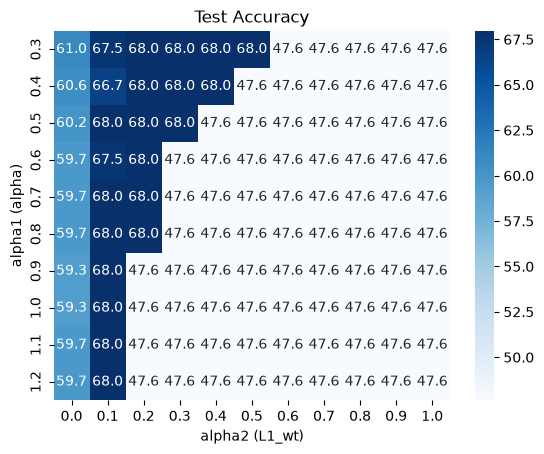

In [76]:
sns.heatmap(results_test, annot = True, fmt = ".1f", cmap = "Blues", xticklabels = np.round(alpha2, 1), yticklabels = np.round(alpha1, 1)) 
plt.xlabel("alpha2 (L1_wt)")
plt.ylabel("alpha1 (alpha)")
plt.title("Test Accuracy")
plt.show()

In [73]:
my_model_genus = sm.GLM(y_train_2, X2_train_S, family = sm.families.Binomial())

alpha1 = np.arange(0.3, 1.21, 0.1)
alpha2 = np.arange(0.0, 1.01, 0.1)


number_models = (len(alpha1) * len(alpha2))

print(f"{number_models} will run") 

results_train_2 = np.zeros((len(alpha1), len(alpha2)))
results_test_2 = np.zeros((len(alpha1), len(alpha2)))

for i, a1 in enumerate(alpha1):
    for j, a2 in enumerate(alpha2):
    
        result_reg = my_model_genus.fit_regularized(method = 'elastic_net', alpha = a1, L1_wt = a2, maxiter = 10000)

        probs_train  = result_reg.predict(X2_train_S)
        probs_test  = result_reg.predict(X2_test_S)
    
        probsR_train = np.round(probs_train)
        probsR_test = np.round(probs_test)
    
        Ypred_train  = probsR_train.astype(int)
        Ypred_test  = probsR_test.astype(int) 

        acc_train = 100*np.mean(np.asarray(Ypred_train) == np.asarray(y_train_2))
        acc_test = 100*np.mean(np.asarray(Ypred_test) == np.asarray(y_test_2))

        results_train_2[i, j] = acc_train
        results_test_2[i, j] = acc_test
print(results_train_2)
print(results_test_2)

110 will run
[[74.80998914 65.58089034 61.02062975 59.17480999 50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [73.83279045 65.03800217 58.74049946 50.59717698 50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [73.50705755 62.64929425 50.59717698 50.59717698 50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [73.07274701 61.67209555 50.59717698 50.59717698 50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [71.55266015 61.23778502 50.59717698 50.59717698 50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [71.00977199 59.39196526 50.59717698 50.59717698 50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [71.00977199 59.17480999 50.59717698 50.59717698 50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [70.79261672 50.59717698 50

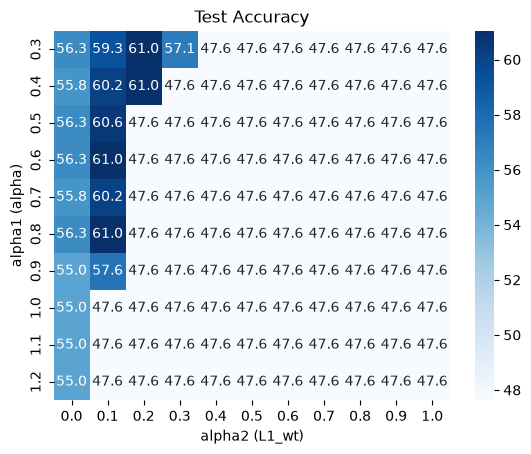

In [77]:
sns.heatmap(results_test_2, annot = True, fmt = ".1f", cmap = "Blues", xticklabels = np.round(alpha2, 1), yticklabels = np.round(alpha1, 1)) 
plt.xlabel("alpha2 (L1_wt)")
plt.ylabel("alpha1 (alpha)")
plt.title("Test Accuracy")
plt.show()

In [78]:
reg_model_sex_genus = my_model_sex_genus.fit_regularized(method = 'elastic_net', alpha = 0.3, L1_wt = 0.4, maxiter = 10000)
reg_model_genus = my_model_genus.fit_regularized(method = 'elastic_net', alpha = 0.3, L1_wt = 0.3, maxiter = 10000)

In [80]:
predprobs   = reg_model_sex_genus.predict(X1_test_S )
pred        = np.round(predprobs).astype(int) 
predictions = ['MS' if i==1 else 'Control' for i in pred] 
accuracy    = 100*(y_test == pred).mean()
print(f'accuracy = {accuracy: .2f}%')

accuracy =  67.97%


In [81]:
predprobs   = reg_model_genus.predict(X2_test_S )
pred        = np.round(predprobs).astype(int) 
predictions = ['MS' if i==1 else 'Control' for i in pred] 
accuracy    = 100*(y_test_2 == pred).mean()
print(f'accuracy = {accuracy: .2f}%')

accuracy =  57.14%


In [ ]:
import statsmodels.formula.api as smf

